# Evaluation & Final Integration — ARTI 502
Evaluates the **initial** and **final (optimized)** versions of both models on the **same official GTSRB test set (12,630 images)**.

| Run | Prediction files (in `results/`) | Final setting |
|---|---|---|
| Custom CNN (initial) | `model1_preds.csv`, `model1_probs.npy` | — |
| Custom CNN (final) | `model1_final_preds.csv`, `model1_final_probs.npy` | dropout 0.7 |
| YOLOv8n-cls (initial) | `model2_preds.csv`, `model2_probs.npy` | — |
| YOLOv8n-cls (final) | `model2_final_preds.csv`, `model2_final_probs.npy` | Mild Erasing 0.2 |

Each `*_preds.csv` has columns `y_true, y_pred`; each `*_probs.npy` has shape `(N, 43)`.

Outputs: metrics table (Tables 8 and 13), comparison chart and per-class F1 (Figures 5 and 6), confusion matrices and ROC curves of the final models (Figures 10 and 11), and an error-overlap analysis.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, os
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix,
                             roc_curve, auc, roc_auc_score)
from sklearn.preprocessing import label_binarize

NUM_CLASSES = 43
BASE    = "/content/drive/MyDrive/ARTI502_Project"
RES_DIR = f"{BASE}/results"; FIG_DIR = f"{BASE}/figures"
os.makedirs(RES_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

# name -> file prefix in results/
RUNS = {
    "Custom CNN (initial)":  "model1",
    "Custom CNN (final)":    "model1_final",
    "YOLOv8n-cls (initial)": "model2",
    "YOLOv8n-cls (final)":   "model2_final",
}
INITIAL = ["Custom CNN (initial)", "YOLOv8n-cls (initial)"]
FINAL   = ["Custom CNN (final)",   "YOLOv8n-cls (final)"]

Mounted at /content/drive


## 1. Load predictions

In [2]:
data = {}
for name, f in RUNS.items():
    df = pd.read_csv(f"{RES_DIR}/{f}_preds.csv")
    probs = np.load(f"{RES_DIR}/{f}_probs.npy")
    assert probs.shape == (len(df), NUM_CLASSES), f"{f}: probs shape {probs.shape}"
    data[name] = {"y_true": df.y_true.values, "y_pred": df.y_pred.values, "probs": probs}
    print(f"{name:24s} {len(df):,} test images")

# All runs must use the same test images in the same order
ref = data[FINAL[0]]["y_true"]
for name, d in data.items():
    assert np.array_equal(d["y_true"], ref), f"{name}: y_true differs from the other runs"
print("\nSame test set and order for all runs ✓")

Custom CNN (initial)     12,630 test images
Custom CNN (final)       12,630 test images
YOLOv8n-cls (initial)    12,630 test images
YOLOv8n-cls (final)      12,630 test images

Same test set and order for all runs ✓


## 2. Metrics table (Table 8 = initial, Table 13 = final)

In [3]:
rows = []
for name, d in data.items():
    yt, yp, pr = d["y_true"], d["y_pred"], d["probs"]
    p_m, r_m, f_m, _ = precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)
    rows.append({"Model": name, "Accuracy": accuracy_score(yt, yp),
                 "Precision (macro)": p_m, "Recall (macro)": r_m, "F1 (macro)": f_m,
                 "ROC-AUC": roc_auc_score(yt, pr, multi_class="ovr", average="macro",
                                          labels=range(NUM_CLASSES)),
                 "Misclassified": int((yt != yp).sum())})
results = pd.DataFrame(rows).set_index("Model")
results.to_csv(f"{RES_DIR}/comparison_table_all.csv")
results.loc[FINAL].to_csv(f"{RES_DIR}/comparison_table_final.csv")
display(results.round(4))

,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC,Misclassified
Model,,,,,,
Custom CNN (initial),0.9360,0.9102,0.9083,0.9033,0.9970,808
Custom CNN (final),0.9488,0.9337,0.9243,0.9235,0.9993,647
YOLOv8n-cls (initial),0.9891,0.9882,0.9830,0.9844,1.0000,138
YOLOv8n-cls (final),0.9859,0.9842,0.9763,0.9793,0.9999,178


## 3. Effect of optimization (final minus initial)

In [4]:
metrics = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)", "ROC-AUC"]
delta = pd.DataFrame({
    "Custom CNN":  results.loc["Custom CNN (final)", metrics]  - results.loc["Custom CNN (initial)", metrics],
    "YOLOv8n-cls": results.loc["YOLOv8n-cls (final)", metrics] - results.loc["YOLOv8n-cls (initial)", metrics],
}).T
display(delta.round(4))

,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC
Custom CNN,0.0127,0.0235,0.0160,0.0202,0.0023
YOLOv8n-cls,-0.0032,-0.0040,-0.0067,-0.0051,-0.0000


## 4. Comparison chart (Figure 5 = initial, plus the final version)

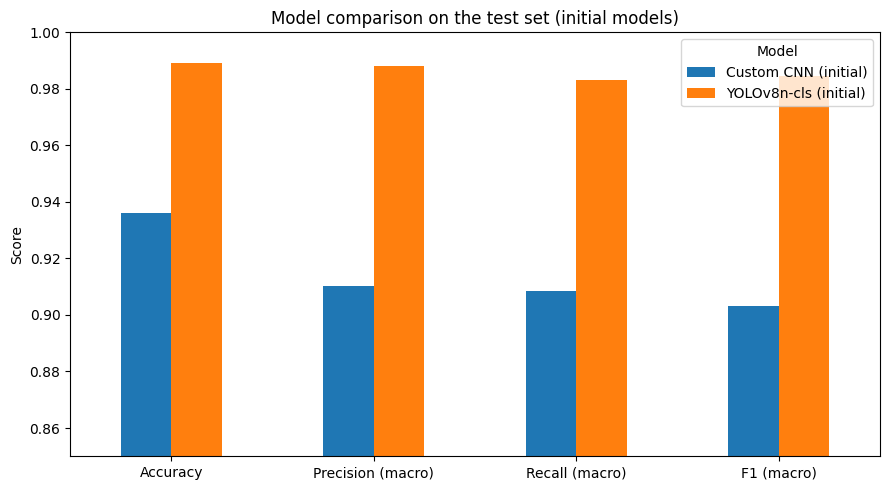

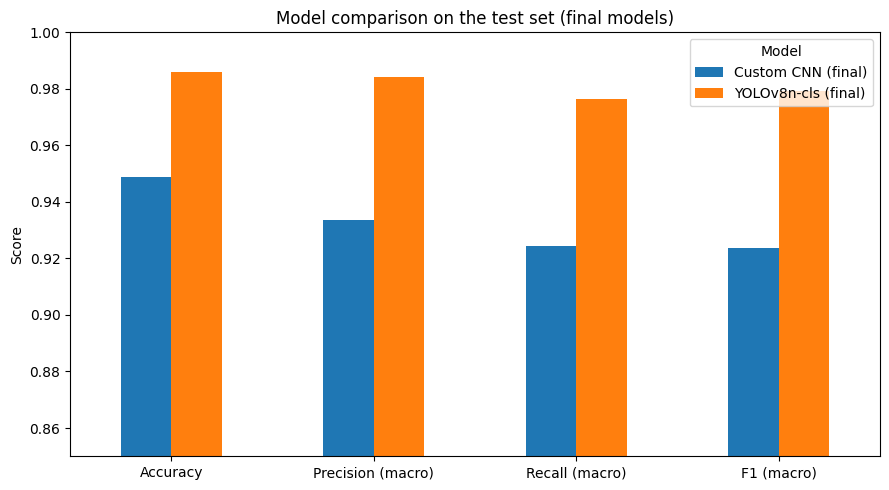

In [5]:
for stage, names in [("initial", INITIAL), ("final", FINAL)]:
    results.loc[names, ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]].T.plot(kind="bar", figsize=(9, 5))
    plt.ylim(0.85, 1.0); plt.ylabel("Score"); plt.xticks(rotation=0)
    plt.title(f"Model comparison on the test set ({stage} models)")
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/model_comparison_{stage}.png", dpi=200); plt.show()

## 5. Per-class F1 (Figure 6 = initial, plus the final version)

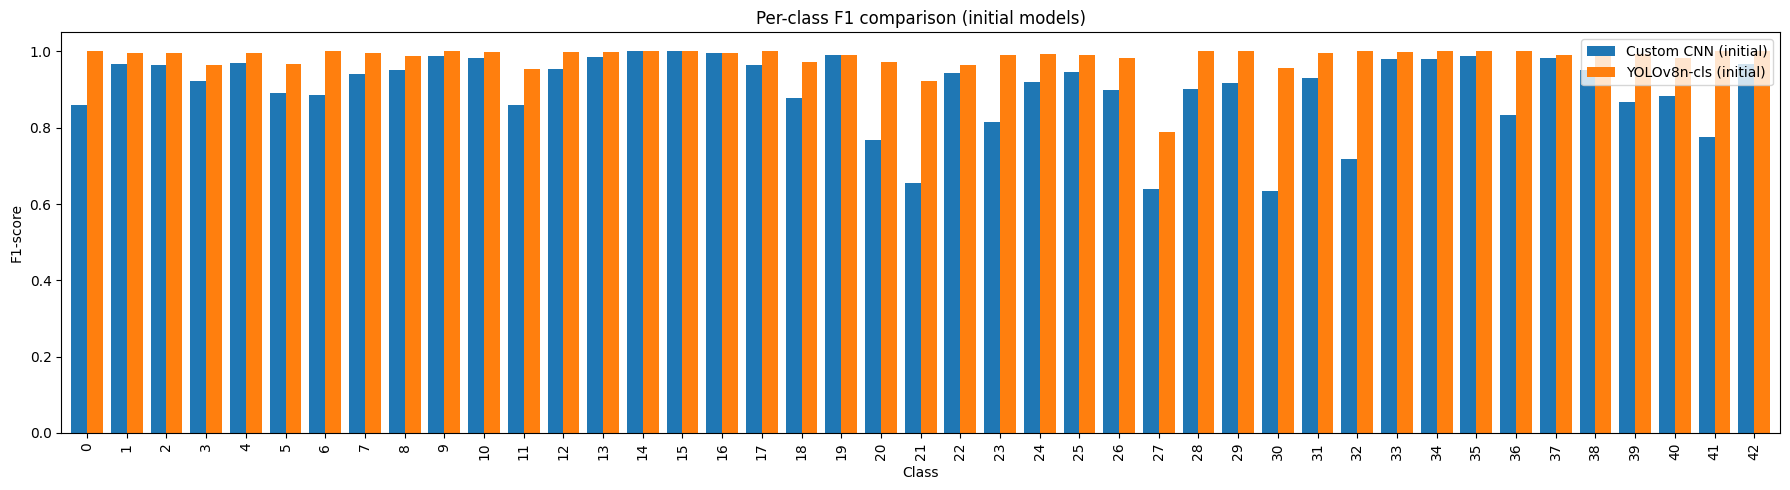

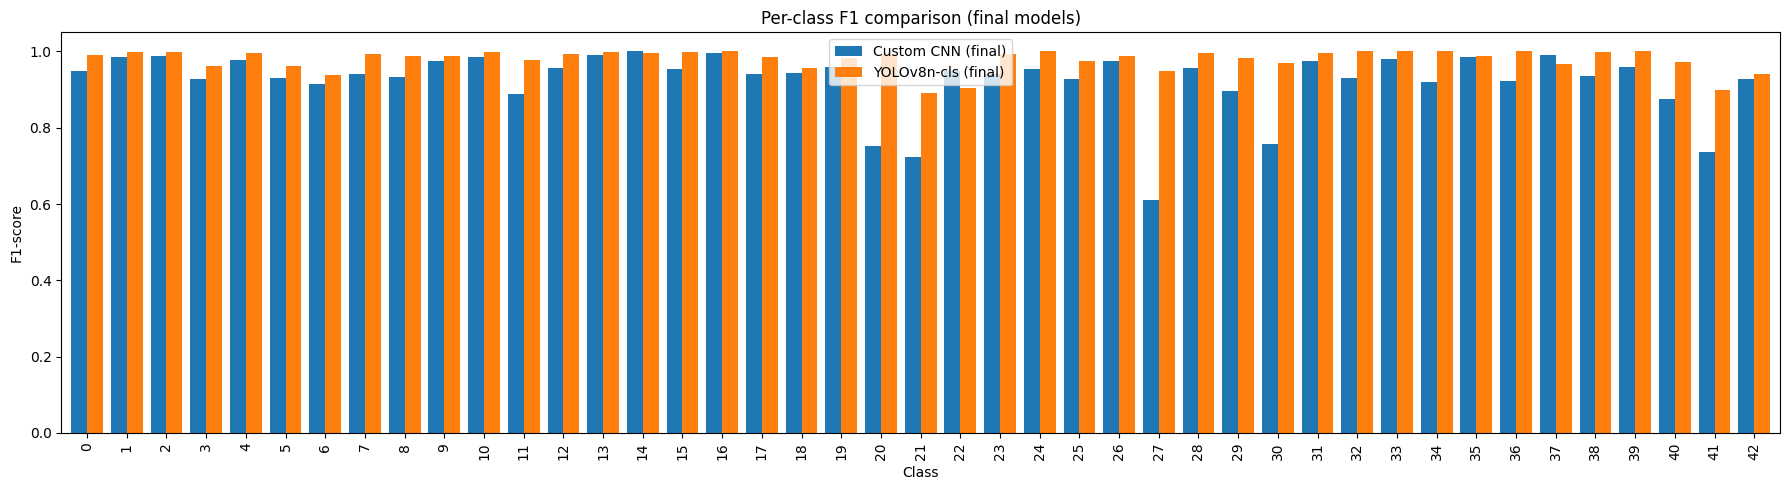

5 weakest classes per model:
Custom CNN (initial)     {30: 0.635, 27: 0.638, 21: 0.654, 32: 0.719, 20: 0.769}
Custom CNN (final)       {27: 0.611, 21: 0.724, 41: 0.737, 20: 0.753, 30: 0.758}
YOLOv8n-cls (initial)    {27: 0.788, 21: 0.923, 11: 0.954, 30: 0.955, 3: 0.963}
YOLOv8n-cls (final)      {21: 0.89, 41: 0.899, 22: 0.904, 6: 0.938, 42: 0.941}


In [6]:
per_class = {}
for name, d in data.items():
    _, _, f, _ = precision_recall_fscore_support(d["y_true"], d["y_pred"], labels=range(NUM_CLASSES), zero_division=0)
    per_class[name] = f
pc = pd.DataFrame(per_class); pc.index.name = "Class"
pc.to_csv(f"{RES_DIR}/per_class_f1_all.csv")

for stage, names in [("initial", INITIAL), ("final", FINAL)]:
    pc[names].plot(kind="bar", figsize=(18, 5), width=0.8)
    plt.ylabel("F1-score"); plt.ylim(0, 1.05); plt.title(f"Per-class F1 comparison ({stage} models)")
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/per_class_f1_{stage}.png", dpi=200); plt.show()

print("5 weakest classes per model:")
for name in pc: print(f"{name:24s}", pc[name].nsmallest(5).round(3).to_dict())

## 6. Confusion matrices of the final models (Figure 10)

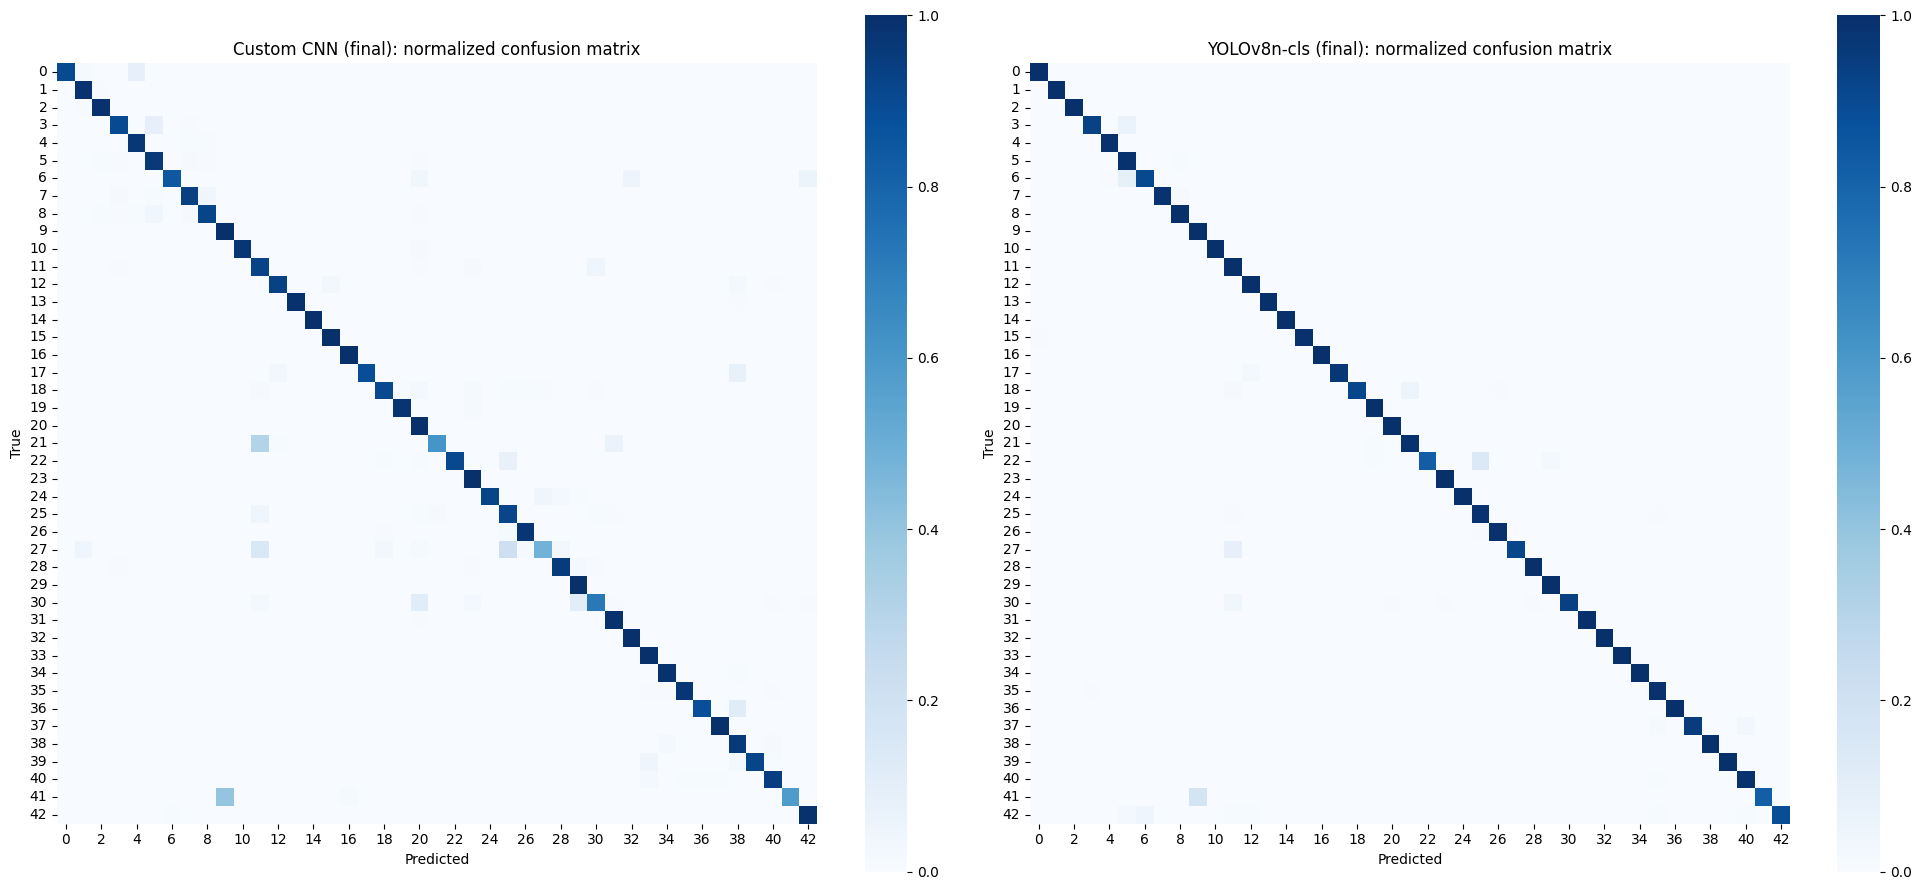

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(20, 9))
for ax, name in zip(axes, FINAL):
    d = data[name]
    cm = confusion_matrix(d["y_true"], d["y_pred"], labels=range(NUM_CLASSES), normalize="true")
    sns.heatmap(cm, ax=ax, cmap="Blues", vmin=0, vmax=1, square=True, cbar=True)
    ax.set_title(f"{name}: normalized confusion matrix"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/confusion_matrices_final.png", dpi=200); plt.show()

## 7. ROC curves of the final models (Figure 11)

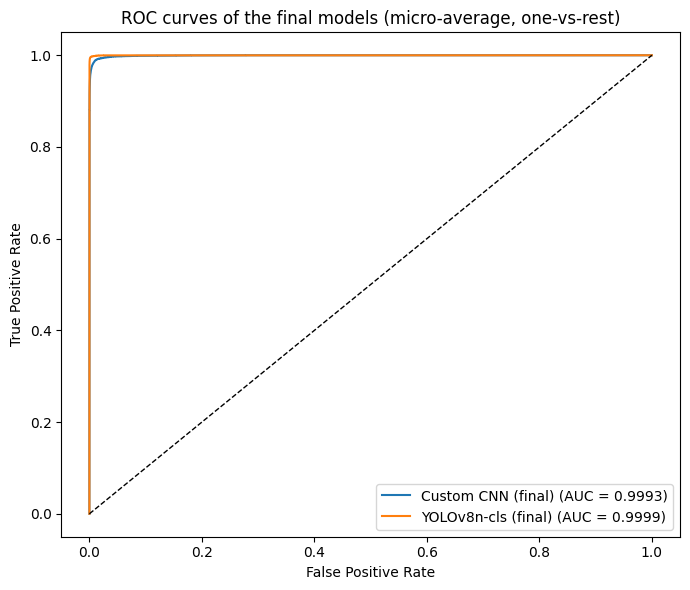

In [8]:
plt.figure(figsize=(7, 6))
for name in FINAL:
    d = data[name]
    yb = label_binarize(d["y_true"], classes=range(NUM_CLASSES))   # micro-average, one-vs-rest
    fpr, tpr, _ = roc_curve(yb.ravel(), d["probs"].ravel())
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curves of the final models (micro-average, one-vs-rest)")
plt.legend(loc="lower right"); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/roc_curves_final.png", dpi=200); plt.show()

## 8. Error overlap between the final models

In [9]:
yt = data[FINAL[0]]["y_true"]
wrong_cnn  = data["Custom CNN (final)"]["y_pred"]  != yt
wrong_yolo = data["YOLOv8n-cls (final)"]["y_pred"] != yt
print("Misclassified by Custom CNN (final): ", wrong_cnn.sum())
print("Misclassified by YOLOv8n-cls (final):", wrong_yolo.sum())
print("Misclassified by both:               ", (wrong_cnn & wrong_yolo).sum())
print("CNN wrong, YOLO correct:             ", (wrong_cnn & ~wrong_yolo).sum())
print("YOLO wrong, CNN correct:             ", (~wrong_cnn & wrong_yolo).sum())

Misclassified by Custom CNN (final):  647
Misclassified by YOLOv8n-cls (final): 178
Misclassified by both:                96
CNN wrong, YOLO correct:              551
YOLO wrong, CNN correct:              82


## 9. Model size and speed (final models)
Parameter counts and inference times were measured in the model notebooks (02, 03, 04).

In [10]:
efficiency = pd.DataFrame({
    "Model": FINAL,
    "Parameters": [361_067, 1_493_371],
    "Inference (ms/image)": [2.51, 13.13],
}).set_index("Model")
final_table = results.loc[FINAL].join(efficiency)
final_table.to_csv(f"{RES_DIR}/final_results_table13.csv")
display(final_table.round(4))

,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC,Misclassified,Parameters,Inference (ms/image)
Model,,,,,,,,
Custom CNN (final),0.9488,0.9337,0.9243,0.9235,0.9993,647,361067,2.51
YOLOv8n-cls (final),0.9859,0.9842,0.9763,0.9793,0.9999,178,1493371,13.13
